# 훈련 세트와 테스트 세트

## 데이터셋 준비
* 총 49개의 데이터
* 0~34번까지는 도미
* 35~48번까지는 빙어

In [2]:
# 각 속성별 데이터
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0,
                31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0,
                35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8,
                10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0,
                500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0,
                700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7,
                7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]
print(len(fish_length), len(fish_weight))

49 49


### 실습1
아래의 코드셀에 학습 데이터와 정답 데이터 구성하는 코드를 직접 작성해 보자

In [5]:
# 학습 데이터 구성
# 여기에 직접 코드를 적어보자
fish_data = [[l, w] for l, w in zip(fish_length, fish_weight)]

## 넘파이의 np.column_stack()를 사용하는 경우도 많음.
import numpy as np
fish_data = np.column_stack((fish_length, fish_weight))

# 정답 데이터 구성(1:도미, 0:빙어)
# 여기에 직접 코드를 적어보자
fish_target = [1]*35 + [0]*14

## 넘파이를 사용하는 경우
fish_target = np.concatenate((np.ones(35), np.zeros(14)))

## [복습] 데이터 슬라이싱

In [6]:
print(fish_data[4])

[ 29. 430.]


In [ ]:
print(fish_data[0:5])

[[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0]]


In [ ]:
print(fish_data[:5])

[[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0]]


In [ ]:
print(fish_data[44:])

[[12.2, 12.2], [12.4, 13.4], [13.0, 12.2], [14.3, 19.7], [15.0, 19.9]]


## 데이터 편향
* 수집된 데이터나 학습용 데이터셋이 특정 방향으로 치우쳐 전체 모집단이나 현실을 공정하게 대표하지 못하는 현상

### 골고루 섞이지 않아서 편향이 발생한 데이터셋

In [7]:
# 훈련세트는 모두 도미로 구성
train_input = fish_data[:35]
train_target = fish_target[:35]

# 테스트세트는 모두 빙어로 구성
test_input = fish_data[35:]
test_target = fish_target[35:]

### 모델 학습 및 정확도 확인

In [8]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()

In [9]:
kn.fit(train_input, train_target)
kn.score(test_input, test_target)

0.0

## 데이터 편향 해결
랜덤하게 섞어서 훈련세트와 테스트세트로 나누자!

In [10]:
import numpy as np

In [11]:
# fish_data와 fish_target을 넘파이 배열로 변경
input_arr = np.array(fish_data)
target_arr = np.array(fish_target)

In [12]:
# input_arr의 값 확인
print(input_arr)

[[  25.4  242. ]
 [  26.3  290. ]
 [  26.5  340. ]
 [  29.   363. ]
 [  29.   430. ]
 [  29.7  450. ]
 [  29.7  500. ]
 [  30.   390. ]
 [  30.   450. ]
 [  30.7  500. ]
 [  31.   475. ]
 [  31.   500. ]
 [  31.5  500. ]
 [  32.   340. ]
 [  32.   600. ]
 [  32.   600. ]
 [  33.   700. ]
 [  33.   700. ]
 [  33.5  610. ]
 [  33.5  650. ]
 [  34.   575. ]
 [  34.   685. ]
 [  34.5  620. ]
 [  35.   680. ]
 [  35.   700. ]
 [  35.   725. ]
 [  35.   720. ]
 [  36.   714. ]
 [  36.   850. ]
 [  37.  1000. ]
 [  38.5  920. ]
 [  38.5  955. ]
 [  39.5  925. ]
 [  41.   975. ]
 [  41.   950. ]
 [   9.8    6.7]
 [  10.5    7.5]
 [  10.6    7. ]
 [  11.     9.7]
 [  11.2    9.8]
 [  11.3    8.7]
 [  11.8   10. ]
 [  11.8    9.9]
 [  12.     9.8]
 [  12.2   12.2]
 [  12.4   13.4]
 [  13.    12.2]
 [  14.3   19.7]
 [  15.    19.9]]


In [ ]:
# input_arr의 모양 확인
print(input_arr.shape)

(49, 2)


### 랜덤 인덱스 만들어 데이터셋 섞기

#### 실습2
랜덤한 인덱스 만들기 코드를 직접 작성해 보자

In [13]:
# 랜덤한 인덱스 만들기
# 1) 0~48까지 값을 생성해서 index 배열에 넣자
# 2) 랜덤하게 섞기
np.random.seed(42)
index = np.arange(49)
np.random.shuffle(index) # shuffle한 결과과 index 배열에 바로 적용됨


In [14]:
print(index)

[13 45 47 44 17 27 26 25 31 19 12  4 34  8  3  6 40 41 46 15  9 16 24 33
 30  0 43 32  5 29 11 36  1 21  2 37 35 23 39 10 22 18 48 20  7 42 14 28
 38]


In [15]:
# 랜덤한 인덱스를 활용해서
# 훈련세트 35개 구성
train_input = input_arr[index[:35]]
train_target = target_arr[index[:35]]
print(train_input)
print(train_target)

[[  32.   340. ]
 [  12.4   13.4]
 [  14.3   19.7]
 [  12.2   12.2]
 [  33.   700. ]
 [  36.   714. ]
 [  35.   720. ]
 [  35.   725. ]
 [  38.5  955. ]
 [  33.5  650. ]
 [  31.5  500. ]
 [  29.   430. ]
 [  41.   950. ]
 [  30.   450. ]
 [  29.   363. ]
 [  29.7  500. ]
 [  11.3    8.7]
 [  11.8   10. ]
 [  13.    12.2]
 [  32.   600. ]
 [  30.7  500. ]
 [  33.   700. ]
 [  35.   700. ]
 [  41.   975. ]
 [  38.5  920. ]
 [  25.4  242. ]
 [  12.     9.8]
 [  39.5  925. ]
 [  29.7  450. ]
 [  37.  1000. ]
 [  31.   500. ]
 [  10.5    7.5]
 [  26.3  290. ]
 [  34.   685. ]
 [  26.5  340. ]]
[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1. 1. 1. 1.
 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1.]


In [16]:
# 랜덤 인덱스 원리 확인
# index 배열의 0번 값이 13이었다면?
print(input_arr[13], train_input[0])

[ 32. 340.] [ 32. 340.]


In [17]:
# 랜덤한 인덱스를 활용해서
# 테스트세트 14개 구성
test_input = input_arr[index[35:]]
test_target = target_arr[index[35:]]

#### 실습3
train_input과 test_input의 length, weight 속성에 대해 산점도 그래프를 그려보자

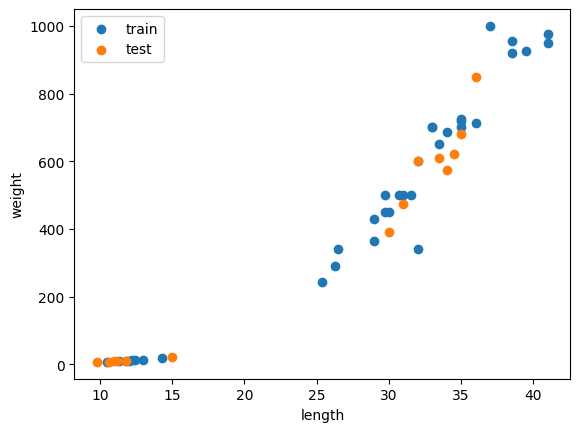

In [19]:
# 산점도 그래프(범례 표시) 그리는 코드를 직접 장성해 보자
import matplotlib.pyplot as plt

plt.scatter(train_input[:, 0], train_input[:, 1], label="train")
plt.scatter(test_input[:, 0], test_input[:, 1], label= 'test')
plt.legend()
plt.xlabel('length')
plt.ylabel('weight')
plt.show()


### 모델 학습 및 정확도 확인

In [20]:
kn.fit(train_input, train_target)

KNeighborsClassifier()

In [21]:
kn.score(test_input, test_target)

1.0

In [22]:
kn.predict(test_input)

array([0., 0., 1., 0., 1., 1., 1., 0., 1., 1., 0., 1., 1., 0.])

In [23]:
test_target

array([0., 0., 1., 0., 1., 1., 1., 0., 1., 1., 0., 1., 1., 0.])

## 사이킷런으로 훈련세트와 테스트세트 나누기

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
# fish_data, fish_target을 넘파이 배열로 변환
# 이유: 넘파이에 있는 함수 쓰기 편리함(예: 모양(shape) 확인 가능)
fish_data = np.array(fish_data)
fish_target = np.array(fish_target)

In [26]:
train_input, test_input, train_target, test_target = train_test_split(
    fish_data, fish_target, random_state=42)

In [27]:
# 훈련세트와 테스트세트의 학습데이터 모양 확인
print(train_input.shape, test_input.shape)

(36, 2) (13, 2)


In [28]:
# 훈련세트와 테스트세트의 정답데이터 모양 확인
print(train_target.shape, test_target.shape)

(36,) (13,)


In [29]:
# 테스트세트의 정답데이터 확인
print(test_target)
print("도미 : ", np.sum(test_target == 1))
print("빙어 : ", np.sum(test_target == 0))

[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
도미 :  10
빙어 :  3


## [최종실습] 사이킷런으로 훈련세트와 테스트세트 나눠 모델 학습시키기
1. 관련 모듈 가져오기: 넘파이, K최근접 이웃 알고리즘, 훈련세트와 테스트세트 나누는 모듈
2. 데이터 준비하기:fish_data, fish_target
3. 사이킷런을 활용하여 훈련세트와 테스트세트 나누기
4. 잘 섞였는지 산점도 그래프로 확인하기
5. 모델 객체 만들기
6. 모델 학습시키기
7. 모델 정확도 확인하기

In [31]:
# 1. 관련 모듈 가져오기:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [32]:
# 2. 데이터 준비하기
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0,
                31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0,
                35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8,
                10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0,
                500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0,
                700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7,
                7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

fish_data = np.array(fish_data)
fish_targget = np.array(fish_target)

In [33]:
# 3. 사이킷런을 활용하여 훈련세트와 테스트세트 나누기
train_input, test_input, train_target, test_target = train_test_split(
    fish_data, fish_target, random_state=42
)
print(train_input)
print(train_target)
print(test_input)
print(test_target)

[[  30.   450. ]
 [  29.   363. ]
 [  29.7  500. ]
 [  11.3    8.7]
 [  11.8   10. ]
 [  13.    12.2]
 [  32.   600. ]
 [  30.7  500. ]
 [  33.   700. ]
 [  35.   700. ]
 [  41.   975. ]
 [  38.5  920. ]
 [  25.4  242. ]
 [  12.     9.8]
 [  39.5  925. ]
 [  29.7  450. ]
 [  37.  1000. ]
 [  31.   500. ]
 [  10.5    7.5]
 [  26.3  290. ]
 [  34.   685. ]
 [  26.5  340. ]
 [  10.6    7. ]
 [   9.8    6.7]
 [  35.   680. ]
 [  11.2    9.8]
 [  31.   475. ]
 [  34.5  620. ]
 [  33.5  610. ]
 [  15.    19.9]
 [  34.   575. ]
 [  30.   390. ]
 [  11.8    9.9]
 [  32.   600. ]
 [  36.   850. ]
 [  11.     9.7]]
[1. 1. 1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1. 0. 0.
 1. 0. 1. 1. 1. 0. 1. 1. 0. 1. 1. 0.]
[[ 32.  340. ]
 [ 12.4  13.4]
 [ 14.3  19.7]
 [ 12.2  12.2]
 [ 33.  700. ]
 [ 36.  714. ]
 [ 35.  720. ]
 [ 35.  725. ]
 [ 38.5 955. ]
 [ 33.5 650. ]
 [ 31.5 500. ]
 [ 29.  430. ]
 [ 41.  950. ]]
[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


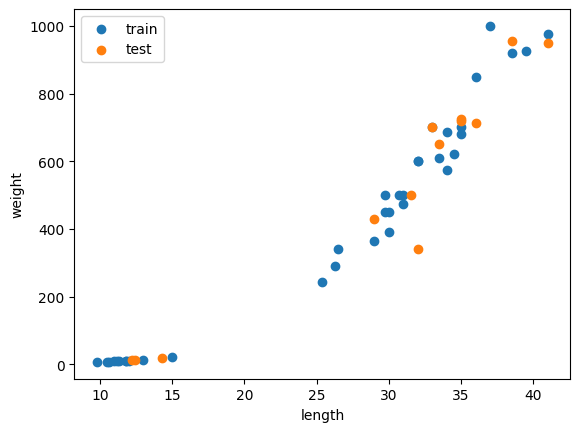

In [35]:
# 4. 잘 섞였는지 산점도 그래프로 확인하기
import matplotlib.pyplot as plt

plt.scatter(train_input[:, 0], train_input[:, 1], label='train')
plt.scatter(test_input[:, 0], test_input[:, 1], label='test')
plt.legend()
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [36]:
# 5. 모델 객체 만들기
kn = KNeighborsClassifier()

In [37]:
# 6. 모델 학습시키기
kn.fit(train_input, train_target)

KNeighborsClassifier()

In [38]:
# 7. 모델 정확도 확인하기
kn.score(test_input, test_target)

1.0